# 22 Zhu et al. 2025 and 2026: their table, EPI, and their classification tested

Zhu et al. (2025, MNRAS 541, 3236) took 29 GBM bursts with a precursor, a main emission and an extended emission, described each with 12 numbers and grouped them with t-SNE and UMAP. Zhu et al. (2026, ApJ 1003, 142) did the same for 366 GBM bursts with a precursor plus GRB 060614, with 9 numbers: the durations of the precursor (T100,PE), the main emission (T100,ME), the whole burst (T100,WE) and the quiet gap after the precursor (T100,QE1), the MVT of the precursor and of the main emission, the lag tau32 of the main emission and of the whole burst, and E_p of the main emission. HDBSCAN on the maps gives 35 Type I-S, 9 Type I-L and 323 Type II, and they condense the result into one index,

EPI = log10[ E_p,ME^2 / (T100,PE T100,QE1^(1/2) T_MVT,PE) ]   (E_p in keV, times in s),

with Type I above 6.2 and Type II below (they adopt 6.2 +/- 0.2). EPI is close to what this project is about, since it uses the precursor to say what kind of progenitor a burst has. Before measuring their bursts again (notebooks 23-26), I check here what can be checked from their own table alone.

1. Their table
2. EPI against their types, and where the line goes
3. Which numbers carry the split
4. Their clustering, repeated
5. How it changes with the settings
6. Clusters without a map
7. Each number left out in turn
8. The circular part, and what the other five numbers carry
9. What this says

The code is in `zhu/classify.py` and `zhu/catalogue.py`, with tests in `tests/test_zhu.py`. The scans in sections 5-8 take about half an hour, so I save them in `results/zhu/classification/` and read them back; the cell that makes each one only runs if its file is missing.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from scipy.stats import spearmanr
from sklearn.metrics import adjusted_rand_score

from zhu import RESULTS, classify as C
from zhu.catalogue import EPI_LINE, EPI_UNSURE, read_table_2026

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
FIGURES = Path("figures")
SCANS = RESULTS / "classification"
COLOURS = {"I-S": "#2a78d6", "I-L": "#eb6834", "II": "0.65"}

table = read_table_2026()
merger = table.Type.str.startswith("I-")
print(len(table), "bursts;", table.Type.value_counts().to_dict())
table[["fermi_id", "Tres", "T100_PE", "T100_QE1", "TMVT_PE", "T100_ME", "TMVT_ME", "T100_WE", "Ep_ME", "tau32_ME_ms", "tau32_WE_ms", "T90", "Type"]].head()

367 bursts; {'II': 323, 'I-S': 35, 'I-L': 9}


,fermi_id,Tres,T100_PE,T100_QE1,TMVT_PE,T100_ME,TMVT_ME,T100_WE,Ep_ME,tau32_ME_ms,tau32_WE_ms,T90,Type
GRB,,,,,,,,,,,,,
060614A,NaN,0.016,0.128,0.544,0.072,6.080,0.008,124.160,302.00,34.51,35.09,123.65,I-L
080715A,080715950,0.032,3.840,2.688,1.936,4.128,0.112,108.896,273.56,28.72,34.67,7.87,II
080830A,080830368,0.064,5.056,3.584,2.016,9.664,2.272,49.280,272.95,-74.83,-240.13,40.90,II
080913B,080913735,0.016,8.608,2.864,0.296,16.528,0.424,28.000,102.94,49.27,46.84,41.22,II
081216A,081216531,0.008,0.152,0.480,0.012,0.464,0.116,1.096,1179.19,19.05,19.34,0.77,I-S


## 1. Their table

Their Table 1 comes as a machine-readable file with the journal, and `catalogue.parse_mrt` reads it into `shared/zhu2026_table1.csv`. All 367 rows are there and no measured value is missing (only GRB 060614, a Swift burst, has no Fermi number). Two things about it matter later. Every T100 is a whole number of their time bins (Tres, 4 to 128 ms, chosen per burst), as differences of block edges are, and every T_MVT is a whole number of half-bins, as half a block's length is. And none of the numbers has an error bar.

## 2. EPI against their types, and where the line goes

In [2]:
above = table.EPI > EPI_LINE
print("adjusted Rand index (ARI) of EPI > 6.2 against their types:", round(adjusted_rand_score(merger, above), 3))
print("bursts on the wrong side:", int((merger != above).sum()), "of", len(table))
print(table[merger != above][["Type", "EPI", "T90", "T100_PE", "T100_QE1", "TMVT_PE", "Ep_ME"]].round(3).to_string())
mixed = table[(table.EPI > EPI_UNSURE[0]) & (table.EPI < EPI_UNSURE[1])]
print("between 6.0 and 6.4:", len(mixed), mixed.Type.value_counts().to_dict())
print("T90 < 2 s against their types: ARI", round(adjusted_rand_score(merger, table.T90 < 2), 3), "; share of their Type I with T90 < 2 s:", round(float((table[merger].T90 < 2).mean()), 2))
print("lowest Type I:", table[merger].EPI.nsmallest(2).round(3).to_dict(), " highest Type II:", table[~merger].EPI.nlargest(2).round(3).to_dict())
for line in (6.04, 6.2, 6.39):
    print(f"   line at {line}: {int(((table.EPI > line) != merger).sum())} on the wrong side, ARI {adjusted_rand_score(merger, table.EPI > line):.3f}")
best, lo, hi, values = C.epi_threshold(table)
print(f"line with the largest true-positive minus false-positive rate: {best:.2f}; bootstrap 68% {lo:.2f}-{hi:.2f}, 95% {np.percentile(values, 2.5):.2f}-{np.percentile(values, 97.5):.2f}")
print(f"   bootstrap values below 6.1: {np.mean(values < 6.1):.2f}, 6.1-6.3: {np.mean((values >= 6.1) & (values <= 6.3)):.3f}, above 6.3: {np.mean(values > 6.3):.2f}")
print("bursts used to name the clusters:")
for name in C.KILONOVA_ANCHORS + C.SHORT_HOST_ANCHORS + C.SUPERNOVA_ANCHORS:
    print(f"   {name}  {table.Type[name]:4s} EPI {table.EPI[name]:5.2f}")

adjusted Rand index (ARI) of EPI > 6.2 against their types: 0.952
bursts on the wrong side: 3 of 367
        Type    EPI    T90  T100_PE  T100_QE1  TMVT_PE   Ep_ME
GRB                                                           
090602A   II  6.267  20.74    0.688     0.560    0.344  572.10
161001A  I-S  6.097   2.24    1.144     0.576    0.196  461.46
221203A   II  6.375   3.52    0.320     0.704    0.112  267.08
between 6.0 and 6.4: 4 {'II': 3, 'I-S': 1}
T90 < 2 s against their types: ARI 0.579 ; share of their Type I with T90 < 2 s: 0.5
lowest Type I: {'161001A': 6.097, '170412B': 6.403}  highest Type II: {'221203A': 6.375, '090602A': 6.267}
   line at 6.04: 3 on the wrong side, ARI 0.952
   line at 6.2: 3 on the wrong side, ARI 0.952
   line at 6.39: 1 on the wrong side, ARI 0.984


line with the largest true-positive minus false-positive rate: 6.04; bootstrap 68% 6.03-6.39, 95% 5.97-6.51
   bootstrap values below 6.1: 0.63, 6.1-6.3: 0.035, above 6.3: 0.34
bursts used to name the clusters:
   211211A  I-L  EPI  8.45
   230307A  I-L  EPI  8.47
   060614A  I-L  EPI  7.13
   090510A  I-S  EPI 11.27
   111117A  I-S  EPI  7.07
   161001A  I-S  EPI  6.10
   090618A  II   EPI  2.12
   111228A  II   EPI  2.84
   180728A  II   EPI  2.67
   190114C  II   EPI  5.50
   190829A  II   EPI  1.31
   211023A  II   EPI  0.81


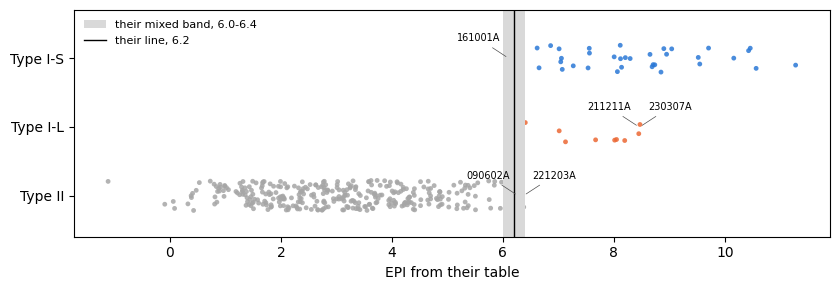

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.0))
rng = np.random.default_rng(1)
rows = {"II": 0, "I-L": 1, "I-S": 2}
for kind, y in rows.items():
    values_k = table.EPI[table.Type == kind]
    ax.scatter(values_k, y + rng.uniform(-0.22, 0.22, len(values_k)), s=12, color=COLOURS[kind], edgecolor="none", alpha=0.85)
ax.axvspan(EPI_UNSURE[0], EPI_UNSURE[1], color="0.85", lw=0, label="their mixed band, 6.0-6.4")
ax.axvline(EPI_LINE, color="k", lw=1.0, label="their line, 6.2")
for name, dx, ha in [("161001A", -6, "right"), ("090602A", -6, "right"), ("221203A", 6, "left"), ("211211A", -6, "right"), ("230307A", 6, "left")]:
    ax.annotate(name, (table.EPI[name], rows[table.Type[name]]), xytext=(dx, 12), textcoords="offset points", ha=ha, fontsize=7,
                arrowprops=dict(arrowstyle="-", lw=0.5, color="0.3"))
ax.set_yticks(list(rows.values()), [f"Type {k}" for k in rows])
ax.set_xlabel("EPI from their table")
ax.set_ylim(-0.6, 2.7)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "22_epi_by_type.png", dpi=150)
plt.show()

EPI does what they say on their own table: 364 of 367 bursts are on the side of 6.2 that matches their type, an adjusted Rand index (ARI) of 0.95. T90 < 2 s gives 0.58, since half of their Type I are long. The three on the wrong side are close to the line: 161001A (Type I-S, 6.10), 090602A (II, 6.27) and 221203A (II, 6.38), and 200101A (II, 6.17) is the fourth burst in the 6.0-6.4 band they call mixed. 161001A is one of the three short bursts in old hosts that they use to name the Type I-S cluster, so one of their reference bursts sits below their line.

Where the line goes is decided by one or two bursts. Every Type I is above 6.40 except 161001A, and every Type II is below 6.38. So any line between 6.10 and 6.38 makes the same three mistakes (ARI 0.952 at both 6.04 and 6.2), and a line just above 6.38 makes one (ARI 0.98). Maximising the true-positive minus false-positive rate puts it at 6.04, because that rate weights each Type I about seven times as much as each Type II. Its bootstrap over bursts has two peaks: 63% of resamples give a value below 6.1 (those with 161001A in them) and 34% above 6.3 (those without), with under 4% in between. Their own band, 6.2 +/- 0.2, is a fair summary of that, and these numbers back it rather than move it.

Of the bursts used to name the clusters, the kilonova bursts are at 7.1-8.5 and the supernova bursts at 0.8-5.5 (the closest is GRB 190114C at 5.5). The three short bursts in old hosts are only "generally considered" Type I-S in their words; 090510 and 111117A are at 11.3 and 7.1, and 161001A is the exception at 6.10.

## 3. Which numbers carry the split

The area under the ROC curve of each number on its own, for Type I against Type II (0.5 is no separation, 1 is complete).

In [4]:
separation = C.single_feature_separation(table)
print("EPI:", round(separation.auc["EPI"], 4))
print("median Tres (s) by type:", table.groupby("Type").Tres.median().to_dict(), "; Spearman correlation of Tres with T90:", round(spearmanr(table.Tres, table.T90).correlation, 2))
for column in ("TMVT_PE", "TMVT_ME"):
    floor = table[column] / table.Tres <= 1.5 + 1e-9
    print(f"{column} at or below 1.5 bins: Type I {floor[merger].mean():.2f}, Type II {floor[~merger].mean():.3f}")
separation.round(3)

EPI: 0.9998
median Tres (s) by type: {'I-L': 0.016, 'I-S': 0.008, 'II': 0.016} ; Spearman correlation of Tres with T90: 0.27
TMVT_PE at or below 1.5 bins: Type I 0.23, Type II 0.000
TMVT_ME at or below 1.5 bins: Type I 0.18, Type II 0.025


,auc,larger_in_type_I
feature,,
EPI,1.000,True
T100_PE,0.986,False
TMVT_PE,0.972,False
T100_QE1,0.957,False
Ep_ME,0.926,True
T100_ME,0.909,False
TMVT_ME,0.890,False
T90,0.849,False
T100_WE,0.845,False


EPI comes out at 0.9998: only 161001A sits below any Type II burst. Of its inputs, T100,PE alone gives 0.986, T_MVT,PE 0.972 and T100,QE1 0.957, which is what Zhu et al. say: Type I are told apart mainly by a shorter precursor, gap and MVT. E_p,ME gives 0.926, about as much as T100,ME. The lags are the weakest numbers (0.72-0.74), weaker than their time bin Tres (0.81).

The time bin isn't a property of a burst, and it is shorter for their Type I-S (a median of 8 ms against 16 ms for Type II), so part of the separation in the timing numbers may reflect the resolution they were measured at. Two signs of that: T_MVT,PE is at or below 1.5 bins for 23% of their Type I and for none of their Type II, and T_MVT,ME for 18% against 2.5%. They don't say how they chose Tres, and it follows T90 only loosely (Spearman correlation 0.27).

## 4. Their clustering, repeated

Their steps (sections 2.3 and 3 of the 2026 paper): log10 of all nine numbers except the two lags, z-scores, t-SNE with perplexity 6 or UMAP with 6 neighbours and min_dist 1e-4, then HDBSCAN from scikit-learn. They don't give HDBSCAN's settings, so I use its defaults (min_cluster_size 5). They name the clusters by the bursts in them: the kilonova bursts (211211A, 230307A, 060614) for Type I-L, the supernova bursts for Type II, and three short bursts in old hosts (090510, 111117A, 161001A) for Type I-S.

In [5]:
x = C.design_matrix(table)
points = C.embed(x, "tsne", 0)
labels = C.clusters(points)
named = C.name_clusters(labels, x.index)
print("t-SNE, perplexity 6:", len(set(labels) - {-1}), "clusters,", round(float(np.mean(labels == -1)), 3), "of the bursts left as noise")
print("agreement with their types:", {k: round(v, 3) for k, v in C.compare(named, table.Type).items()})
for c in sorted(set(labels[(named == "merger").values])):
    members = x.index[labels == c]
    anchors = [n for n in members if n in C.KILONOVA_ANCHORS + C.SHORT_HOST_ANCHORS]
    print(f"merger cluster {c}: {len(members)} bursts, their types {table.Type[members].value_counts().to_dict()}, anchors {anchors}")
sn_clusters = sorted(set(labels[(named == "collapsar").values]))
others = sorted(set(labels) - {-1} - set(labels[(named == "merger").values]) - set(sn_clusters))
print(f"clusters with a supernova burst: {len(sn_clusters)}; other clusters: {len(others)}; noise: {int(np.sum(labels == -1))} bursts,",
      "supernova bursts in the noise:", [n for n in x.index[labels == -1] if n in C.SUPERNOVA_ANCHORS])
for seed in range(3):
    row, _ = C.one_run(x, table.Type, "umap", seed)
    print(f"UMAP seed {seed}: {row['n_clusters']} clusters, ARI {row['ari']:.3f}")

t-SNE, perplexity 6: 26 clusters, 0.155 of the bursts left as noise
agreement with their types: {'type_I_recovered': 1.0, 'type_II_recovered': 1.0, 'ari': 1.0, 'type_II_in_sn_cluster': 0.161}
merger cluster 0: 9 bursts, their types {'I-L': 9}, anchors ['060614A', '211211A', '230307A']
merger cluster 1: 35 bursts, their types {'I-S': 35}, anchors ['090510A', '111117A', '161001A']
clusters with a supernova burst: 4; other clusters: 20; noise: 57 bursts, supernova bursts in the noise: ['211023A']


UMAP seed 0: 31 clusters, ARI 0.497


UMAP seed 1: 27 clusters, ARI 1.000


UMAP seed 2: 25 clusters, ARI 1.000


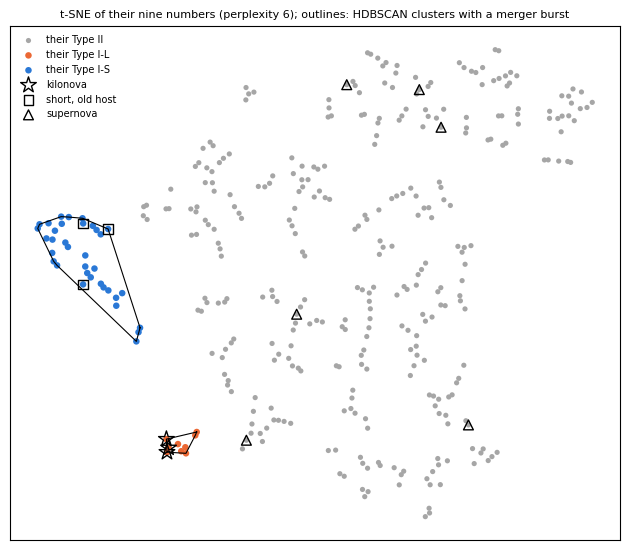

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for kind in ("II", "I-L", "I-S"):
    inside = (table.Type == kind).values
    ax.scatter(points[inside, 0], points[inside, 1], s=14 if kind == "II" else 22, color=COLOURS[kind], edgecolor="none", label=f"their Type {kind}", zorder=2 if kind == "II" else 3)
for c in set(labels[(named == "merger").values]):
    inside = labels == c
    hull = ConvexHull(points[inside])
    loop = np.r_[hull.vertices, hull.vertices[0]]
    ax.plot(points[inside][loop, 0], points[inside][loop, 1], color="k", lw=0.8, zorder=4)
markers = {"kilonova": (C.KILONOVA_ANCHORS, "*", 140), "short, old host": (C.SHORT_HOST_ANCHORS, "s", 50), "supernova": (C.SUPERNOVA_ANCHORS, "^", 50)}
for label, (names, marker, size) in markers.items():
    inside = x.index.isin(names)
    ax.scatter(points[inside, 0], points[inside, 1], marker=marker, s=size, facecolor="none", edgecolor="k", lw=1.0, label=label, zorder=5)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("t-SNE of their nine numbers (perplexity 6); outlines: HDBSCAN clusters with a merger burst", fontsize=8)
ax.legend(frameon=False, fontsize=7, loc="best")
fig.tight_layout()
fig.savefig(FIGURES / "22_tsne_map.png", dpi=150)
plt.show()

This gives their types exactly. In scikit-learn, t-SNE starts from the first two principal components, so the map is the same every time, and the clusters that hold a merger burst contain exactly their 44 Type I: one of 35 with the three short bursts in old hosts, one of 9 with the three kilonova bursts (ARI 1.000). UMAP depends on its seed, and 2 of the 3 seeds above give their types exactly.

At these settings HDBSCAN finds 26 clusters rather than three, and leaves 16% of the bursts as noise. Besides the two merger clusters, 4 hold a supernova burst, and the other 20 clusters and the noise (which includes the supernova burst 211023A) hold the rest. So at their stated settings their Type II is made of 24 small clusters and the noise, and only about a sixth of it sits in a cluster with a supernova burst. Section 5 shows this changes with the settings: at some larger neighbourhoods HDBSCAN finds exactly their three classes, with Type II as one cluster.

## 5. How it changes with the settings

The same steps over a range of settings: t-SNE perplexity from 3 to 50 (from the principal components, and from random starts with 20 seeds), UMAP n_neighbors from 3 to 50 at their min_dist and at 0.1 (20 seeds each), and HDBSCAN's min_cluster_size from 3 to 20 at their map settings. The score is the ARI of "in a merger cluster" against their types.

In [7]:
path = SCANS / "robustness.csv"
if not path.exists():
    SCANS.mkdir(parents=True, exist_ok=True)
    C.robustness(table).to_csv(path, index=False)
scan = pd.read_csv(path)
scan["exact"] = scan.ari > 0.999
scan["above_0.9"] = scan.ari > 0.9
maps = scan[scan.scan.isna()]
sizes = scan[scan.scan == "min_cluster_size"]
summary = lambda d, keys: d.groupby(keys).agg(runs=("ari", "size"), median_ari=("ari", "median"), exact=("exact", "mean"), above_09=("above_0.9", "mean"),
                                               clusters=("n_clusters", "median"), clusters_max=("n_clusters", "max"), type_I_in_merger=("type_I_recovered", "median")).round(2)
print("t-SNE")
print(summary(maps[maps.method == "tsne"], ["init", "perplexity"]).to_string())
print("UMAP")
print(summary(maps[maps.method == "umap"], ["min_dist", "n_neighbors"]).to_string())
print("HDBSCAN min_cluster_size")
print(summary(sizes, ["method", "min_cluster_size"]).to_string())
three = scan[(scan.n_clusters == 3) & scan.exact]
print(len(three), "runs find exactly three clusters that are their three types; share of their Type II in the supernova cluster in those runs:",
      round(three.type_II_in_sn_cluster.min(), 3), "-", round(three.type_II_in_sn_cluster.max(), 3))
print(three[["method", "init", "perplexity", "n_neighbors", "min_dist", "seed", "noise"]].to_string(index=False))

t-SNE
                   runs  median_ari  exact  above_09  clusters  clusters_max  type_I_in_merger
init   perplexity                                                                             
pca    3.0            1        0.52   0.00      0.00      28.0            28              0.48
       4.0            1        0.64   0.00      0.00      25.0            25              0.57
       5.0            1        0.93   0.00      1.00      18.0            18              0.91
       6.0            1        1.00   1.00      1.00      26.0            26              1.00
       8.0            1        1.00   1.00      1.00      17.0            17              1.00
       10.0           1        0.85   0.00      0.00       2.0             2              0.80
       15.0           1        0.85   0.00      0.00       2.0             2              0.80
       20.0           1        1.00   1.00      1.00       3.0             3              1.00
       30.0           1        0.81   0.00  

                         runs  median_ari  exact  above_09  clusters  clusters_max  type_I_in_merger
method min_cluster_size                                                                             
tsne   3                    1        0.69   0.00      0.00      51.0            51              0.61
       4                    1        1.00   1.00      1.00      30.0            30              1.00
       5                    1        1.00   1.00      1.00      26.0            26              1.00
       6                    1        1.00   1.00      1.00      17.0            17              1.00
       8                    1        0.95   0.00      1.00      10.0            10              0.93
       10                   1        0.78   0.00      0.00       2.0             2              0.73
       15                   1        0.78   0.00      0.00       2.0             2              0.73
       20                   1        0.77   0.00      0.00       2.0             2         

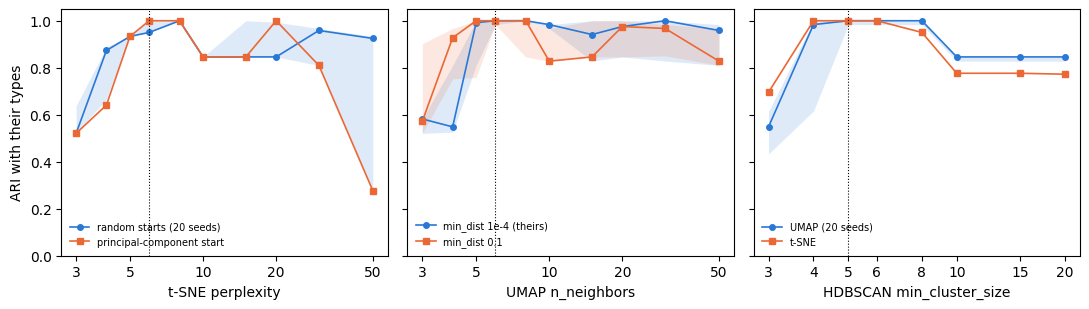

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
def band(ax, d, key, label, colour, marker="o"):
    g = d.groupby(key).ari
    ax.plot(g.median().index, g.median().values, marker=marker, ms=4, color=colour, lw=1.2, label=label)
    if g.size().max() > 1:
        ax.fill_between(g.median().index, g.quantile(0.16).values, g.quantile(0.84).values, color=colour, alpha=0.15, lw=0)
ts = maps[maps.method == "tsne"]
band(axes[0], ts[ts.init == "random"], "perplexity", "random starts (20 seeds)", "#2a78d6")
band(axes[0], ts[ts.init == "pca"], "perplexity", "principal-component start", "#eb6834", "s")
um = maps[maps.method == "umap"]
band(axes[1], um[um.min_dist < 0.01], "n_neighbors", "min_dist 1e-4 (theirs)", "#2a78d6")
band(axes[1], um[um.min_dist > 0.01], "n_neighbors", "min_dist 0.1", "#eb6834", "s")
band(axes[2], sizes[sizes.method == "umap"], "min_cluster_size", "UMAP (20 seeds)", "#2a78d6")
band(axes[2], sizes[sizes.method == "tsne"], "min_cluster_size", "t-SNE", "#eb6834", "s")
for ax, xlabel, theirs, ticks in zip(axes, ["t-SNE perplexity", "UMAP n_neighbors", "HDBSCAN min_cluster_size"], [6, 6, 5],
                                     [[3, 5, 10, 20, 50], [3, 5, 10, 20, 50], [3, 4, 5, 6, 8, 10, 15, 20]]):
    ax.axvline(theirs, color="k", lw=0.8, ls=":")
    ax.set_xscale("log")
    ax.set_xticks(ticks, [str(t) for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel(xlabel)
    ax.legend(frameon=False, fontsize=7, loc="lower left")
axes[0].set_ylabel("ARI with their types")
axes[0].set_ylim(0, 1.05)
fig.tight_layout()
fig.savefig(FIGURES / "22_classification_settings.png", dpi=150)
plt.show()

Their result holds over a range of settings around theirs, and changes outside it.

- t-SNE: from random starts, perplexity 6 gives their types exactly for 40% of seeds and with an ARI above 0.9 for 90%, and perplexity 8 exactly for 85%. At 3 the merger clusters break up (median ARI 0.52). At 10-20 HDBSCAN mostly finds two clusters and the median ARI is 0.85, though perplexity 20 gives their types exactly from the principal-component start and for 20% of random starts. At 30 and 50 the medians are 0.96 and 0.92 from random starts, but 0.81 and 0.28 from the principal-component start, which is scikit-learn's default.
- UMAP: with their min_dist, 6 neighbours gives their types exactly for 70% of seeds and with an ARI above 0.9 for 95%. From 5 to 10 neighbours the exact share is 10-85% and the median ARI 0.98-1.00. Below 5 it falls to 0.55-0.58, and above 10 the median stays at 0.94-1.00 with 50-75% of seeds above 0.9.
- HDBSCAN: with min_cluster_size 4-6 their types come back (exactly for t-SNE, above 0.9 for 55-100% of UMAP seeds), and with 8 nearly. From 10 up it mostly finds two clusters (UMAP sometimes more), and the merger cluster holds 70-73% (t-SNE) or 80% (UMAP) of their Type I, an ARI of 0.77-0.85. Their Type I-L cluster has 9 members, so it can't exist with a minimum of 10.

In 15 runs HDBSCAN finds exactly three clusters that are their three types, with 98-100% of their Type II in one cluster and almost no noise: t-SNE at perplexity 8, 15 and 20 for some seeds, and UMAP with min_dist 0.1. So their three classes do appear as three clusters for some seeds and settings, while at their stated settings they appear as 26.

Zhu et al. checked perplexity and n_neighbors of 5, 6 and 7 with different random starts and found the result consistent, and over that range I agree. The scan shows how far it extends: the merger group is stable for small neighbourhoods and small minimum cluster sizes and changes outside them.

## 6. Clusters without a map

t-SNE and UMAP are built to draw clusters: they keep neighbours together and move everything else freely. A plainer test is to model the nine numbers themselves as a mixture of Gaussians and let the Bayesian information criterion (BIC) choose how many components there are, and to run HDBSCAN on the nine numbers directly. For each mixture I look at the component holding the most of their Type I, with three kinds of covariance: each component its own (full), one shared by all (tied), and no correlations (diag).

In [9]:
path = SCANS / "mixtures.csv"
if not path.exists():
    C.mixture_in_feature_space(x, table.Type).to_csv(path, index=False)
mixtures = pd.read_csv(path)
print(mixtures.round(3).to_string(index=False))
path = SCANS / "feature_space_hdbscan.csv"
if not path.exists():
    C.hdbscan_in_feature_space(x, table.Type).to_csv(path, index=False)
print("HDBSCAN on the nine numbers themselves:")
pd.read_csv(path).round(3)

covariance  components      bic              sizes  top_size  top_type_I  top_type_II   ari
      full           1 7131.169                367       367          44          323 0.000
      full           2 6064.834            207 160       207          44          163 0.002
      full           3 5800.448         149 145 73       145          44          101 0.180
      full           4 5821.859      120 70 52 125        70          44           26 0.662
      full           5 5930.171    36 79 42 125 85        36          33            3 0.766
      full           6 5885.194  34 97 18 52 78 88        34          32            2 0.762
      tied           1 7131.169                367       367          44          323 0.000
      tied           2 7026.445             45 322        45          35           10 0.707
      tied           3 6882.544          303 45 19        45          35           10 0.707
      tied           4 6888.061      140 45 18 164        45          35        

,min_cluster_size,n_clusters,noise,type_I_recovered,type_II_recovered,ari,type_II_in_sn_cluster
0,4,3,0.281,0.136,1.0,0.191,0.000
1,5,2,0.185,0.477,1.0,0.570,0.000
2,6,2,0.221,0.364,1.0,0.456,0.827
3,8,2,0.248,0.000,1.0,0.000,0.000
4,10,2,0.264,0.227,1.0,0.304,0.802
5,15,0,1.000,0.000,1.0,0.000,0.000
6,20,0,1.000,0.000,1.0,0.000,0.000


With a full covariance for each component, which the BIC prefers over the simpler kinds at every size, three components are best (BIC 5800). All 44 of their Type I fall in one of them, but it has 145 members, 101 of them Type II (ARI 0.18). A fourth component, which the BIC doesn't prefer (by 21), splits off 70 bursts holding all 44 Type I and 26 Type II (ARI 0.66). With simpler covariances a component close to Type I does appear: 35 Type I with 10 Type II with one shared covariance (ARI 0.71), and 42 Type I with 8 Type II with no correlations at three components (ARI 0.85). Those models fit much worse, though (BIC 6490 and up). HDBSCAN on the nine numbers themselves leaves 19-28% of the bursts as noise and recovers at most about half of their Type I (ARI up to 0.57).

So under the mixture the data prefer, their Type I sit inside a larger group with Type II, and they come out as a group of their own in the maps and in the simpler mixtures. That is a result for these models; a different one could draw the line differently.

## 7. Each number left out in turn

The UMAP map and HDBSCAN again, with one of the nine numbers left out each time, over 20 seeds.

In [10]:
path = SCANS / "leave_one_out.csv"
if not path.exists():
    C.leave_one_out(table).to_csv(path)
pd.read_csv(path, index_col=0).round(3)

,ari_mean,ari_spread,ari_lowest,exact,type_I_recovered,n_clusters
left_out,,,,,,
none,0.971,0.112,0.497,0.70,0.988,26.0
T100_PE,0.838,0.131,0.600,0.00,0.811,29.0
T100_ME,0.984,0.015,0.936,0.30,0.983,27.0
T100_WE,0.843,0.205,0.407,0.55,0.808,28.0
T100_QE1,0.571,0.183,0.357,0.00,0.495,30.0
TMVT_PE,0.847,0.101,0.613,0.00,0.816,28.5
TMVT_ME,0.590,0.068,0.535,0.00,0.583,32.0
tau32_ME_ms,0.876,0.166,0.570,0.40,0.861,28.5
tau32_WE_ms,0.899,0.156,0.499,0.30,0.914,25.0


With all nine, the 20 seeds give a mean ARI of 0.97 (exact for 70%). Three numbers stand out: without E_p,ME the mean falls to 0.56, without T100,QE1 to 0.57 and without T_MVT,ME to 0.59, and their types never come back exactly. Leaving out T100,PE, T_MVT,PE or T100,WE gives about 0.84, leaving out a lag 0.88-0.90, and leaving out T100,ME changes nothing (0.98). T100,PE and T_MVT,PE partly stand in for each other, so dropping one costs less than dropping E_p,ME. T_MVT,ME matters as much as E_p,ME here, and EPI leaves it out.

## 8. The circular part, and what the other five numbers carry

Their types come from clustering the nine numbers, and EPI combines four of them, chosen after seeing which separate the clusters. So EPI agreeing with their types at 0.95 is an in-sample result: it shows that a formula fitted to describe the clusters describes them, but it isn't independent evidence that EPI finds progenitors. They say as much ("Assuming that the UMAP classification reflects the true origins"). The independent checks are the bursts of known origin (section 2), new measurements (notebooks 23-25), and choosing the line on some bursts and scoring it on others (notebook 26).

What I can test here is how much of the split the other five numbers carry on their own. I make groups from T100,ME, T100,WE, T_MVT,ME and the two lags only, and name them by the same bursts. They share no column with EPI, but they share some information: T100,WE is T100,PE + T100,QE1 + T100,ME for every burst without extended emission (282 of 367), and tau32,WE covers the precursor too.

In [11]:
print("T100,WE = T100,PE + T100,QE1 + T100,ME for", int((np.abs(table.T100_PE + table.T100_QE1 + table.T100_ME - table.T100_WE) < 1e-6).sum()), "bursts")
path = SCANS / "without_epi_inputs.csv"
if not path.exists():
    C.without_epi_inputs(table).to_csv(path, index=False)
independent = pd.read_csv(path)
print(independent.round(3).to_string(index=False))
print("median ARI with EPI:", round(independent.ari_with_epi.median(), 2), " with their types:", round(independent.ari_with_types.median(), 2),
      "; difference in each seed:", round((independent.ari_with_types - independent.ari_with_epi).min(), 3), "-", round((independent.ari_with_types - independent.ari_with_epi).max(), 3))
print("bursts above 6.2:", int(above.sum()))

T100,WE = T100,PE + T100,QE1 + T100,ME for 282 bursts
 seed  n_merger  ari_with_epi  epi_agrees  ari_with_types
    0        32         0.379       0.894           0.416
    1        32         0.585       0.932           0.628
    2        25         0.509       0.924           0.553
    3        24         0.489       0.921           0.532
    4        24         0.489       0.921           0.532
    5        23         0.468       0.918           0.511
    6        25         0.509       0.924           0.553
    7        32         0.585       0.932           0.628
    8        23         0.468       0.918           0.511
    9        33         0.398       0.896           0.435
median ARI with EPI: 0.49  with their types: 0.53 ; difference in each seed: 0.037 - 0.044
bursts above 6.2: 45


These groups have 23-33 merger bursts, against 45 above 6.2, and they agree with EPI at an ARI of 0.38-0.59 (median 0.49) and with their types at 0.42-0.63 (median 0.53). In every seed the two differ by about 0.04, so the groups match EPI about as well as they match the types EPI was built on. The five numbers carry part of the split, less than the four EPI uses, which fits what Zhu et al. found when they left the precursor numbers out of their maps. This test doesn't measure how much of EPI's 0.95 is circular; that needs the line or the exponents chosen on one set of bursts and scored on another, which notebook 26 does.

## 9. What this says

- Their table reproduces. EPI as they define it gives their ARI of 0.95 at 6.2 and their four mixed bursts between 6.0 and 6.4, and t-SNE at their settings with scikit-learn's defaults gives exactly their 44 Type I.
- The line is set by one burst. 161001A, one of their reference short bursts, is at 6.10, and any line from 6.10 to 6.38 makes the same three mistakes. Their 6.2 +/- 0.2 is a fair summary.
- Their three classes come back for small neighbourhoods and small minimum cluster sizes, the range they tested, and change outside it. At their stated settings Type II is 24 small clusters and the noise; at some larger neighbourhoods it is one cluster.
- In the nine numbers themselves, under the mixture the BIC prefers, their Type I sit inside a larger group; the maps and simpler mixtures separate them.
- E_p,ME, T100,QE1 and T_MVT,ME matter most to the clustering, and T100,ME doesn't matter at all.
- EPI's 0.95 is in-sample, and the five numbers outside EPI carry part of the same split (ARI about 0.5).
- The precursor's timing separates their types better than any other single number: T100,PE alone gives an area of 0.986, as Zhu et al. say. Whether that holds when the numbers are measured again, with errors, is what notebooks 23-26 test.